# Pronóstico a 10 minutos de la actividad de Internet en Milán
**Técnicas Avanzadas de Modelado en IA · Unidad 4 · Proyecto integrador**
**David Santiago Iriarte Zamora y Jose Adrian Trochez Cuellar · Grupo 12**

**Pregunta.** ¿Una red recurrente (LSTM o GRU) reduce el error de pronóstico del siguiente intervalo de 10 minutos de la actividad de Internet de Milán frente a líneas base sencillas, evaluadas con la misma partición?

**Datos.** Telecom Italia Big Data Challenge, *SMS, Call, Internet - MI*, primera semana (4 al 10 de noviembre de 2013), agregada a una serie de 1.008 intervalos de 10 minutos (`datos/milan_internet_aggregated.csv`). La variable `internet_sum` es un índice de actividad, no bytes ni usuarios.

**Protocolo.**
1. Partición cronológica 70/15/15, escaladores ajustados solo con entrenamiento.
2. Líneas base sobre las mismas ventanas: persistencia, deriva, media de ventana, ingenuo diario y regresión Ridge.
3. Ronda 1: reproducción de los cinco experimentos del avance (objetivo = nivel).
4. Ronda 2: cambio de formulación (objetivo = cambio respecto al último valor) y de entradas (calendario).
5. Ronda 3: búsqueda en malla de tasa de aprendizaje, *dropout* y optimizador para LSTM y GRU.
6. Selección **solo con validación** (media de 3 semillas: 42, 7 y 2026), una evaluación en prueba, intervalos por *bootstrap* de bloques y prueba de Diebold-Mariano.
7. Curvas de aprendizaje, análisis de errores, costos y exportación de pesos.

El notebook corre de principio a fin en CPU (unos 6 minutos en un Mac M4 Pro). Cada corrida queda registrada en MLflow (`mlruns/`) y en `salidas/experimentos.csv`.

## 0. Configuración y reproducibilidad

In [1]:
import os, json, time, random, hashlib, platform, warnings
from pathlib import Path
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "3"
os.environ["MLFLOW_ALLOW_FILE_STORE"] = "true"
os.environ["MLFLOW_DISABLE_AGENT_HINT"] = "1"
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge
import tensorflow as tf
tf.get_logger().setLevel("ERROR")
try:
    import mlflow
    import logging; logging.getLogger("mlflow").setLevel(logging.ERROR)
    USAR_MLFLOW = True
except ImportError:          # el registro CSV se conserva aunque falte MLflow
    USAR_MLFLOW = False

# Raíz del proyecto: la carpeta que contiene datos/milan_internet_aggregated.csv
RAIZ = Path.cwd()
while not (RAIZ / "datos" / "milan_internet_aggregated.csv").exists() and RAIZ != RAIZ.parent:
    RAIZ = RAIZ.parent
CSV = RAIZ / "datos" / "milan_internet_aggregated.csv"
if not CSV.exists():         # Colab u otra máquina sin el repositorio clonado
    RAIZ = Path.cwd(); CSV = RAIZ / "datos" / "milan_internet_aggregated.csv"
    CSV.parent.mkdir(parents=True, exist_ok=True)
    URL = ("https://raw.githubusercontent.com/dsiriarte/Tecnicas-Avanzadas-de-Modelado-en-IA/"
           "main/Unidad%204/datos/milan_internet_aggregated.csv")
    import urllib.request; urllib.request.urlretrieve(URL, CSV)
SAL, MOD = RAIZ / "salidas", RAIZ / "modelos"
SAL.mkdir(exist_ok=True); MOD.mkdir(exist_ok=True)

SEMILLAS = [42, 7, 2026]
LOOKBACK = 12                   # 12 pasos x 10 min = 2 horas de contexto
EPOCAS_MAX, LOTE = 150, 32       # mismo presupuesto para todas las redes
PACIENCIA_ES, PACIENCIA_LR = 15, 6
SHA256_ESPERADO = "924333a3058a15efa3d424b4e9721a84372e2fd48b90b9d03d1485e463ff1484"

def fijar_semilla(s):
    os.environ["PYTHONHASHSEED"] = str(s)
    random.seed(s); np.random.seed(s); tf.keras.utils.set_random_seed(s)
tf.config.experimental.enable_op_determinism()
fijar_semilla(42)

sha = hashlib.sha256(CSV.read_bytes()).hexdigest()
assert sha == SHA256_ESPERADO, "El CSV no coincide con la versión del informe"
print("Python", platform.python_version(), "| TensorFlow", tf.__version__, "| Keras", tf.keras.__version__,
      "| scikit-learn", sklearn.__version__, "| pandas", pd.__version__, "| numpy", np.__version__)
print("MLflow:", mlflow.__version__ if USAR_MLFLOW else "no instalado (solo CSV)")
print("GPU:", tf.config.list_physical_devices("GPU") or "ninguna (CPU)")
print("Raíz:", RAIZ.name, "| SHA-256 del CSV verificado:", sha[:12], "...")

Python 3.12.11 | TensorFlow 2.21.0 | Keras 3.15.1 | scikit-learn 1.9.1 | pandas 3.0.5 | numpy 2.5.3
MLflow: 3.17.2
GPU: ninguna (CPU)
Raíz: Unidad 4 | SHA-256 del CSV verificado: 924333a3058a ...


## 1. Carga, auditoría y calendario

In [2]:
df = pd.read_csv(CSV)
df["ts_utc"] = pd.to_datetime(df["timestamp_utc"], utc=True)
df = df.sort_values("ts_utc").reset_index(drop=True)
df["ts_local"] = df["ts_utc"].dt.tz_convert("Europe/Rome")      # Milán, UTC+1 en noviembre
assert len(df) == 1008 and df["internet_sum"].notna().all()
assert (df["ts_utc"].diff().iloc[1:] == pd.Timedelta(minutes=10)).all()
y = df["internet_sum"].to_numpy("float64")
N = len(y)
audit = json.loads((RAIZ / "datos" / "milan_data_audit.json").read_text())
print(f"Registros originales: {audit['total_rows']:,} | celdas: {audit['unique_cells']:,} | "
      f"internet ausente: {audit['missing_internet_total']/audit['total_rows']:.1%}")
print(f"Serie: {N} intervalos, {df.ts_local.min()} a {df.ts_local.max()} (hora local)")
print(f"internet_sum: min {y.min():,.0f} | mediana {np.median(y):,.0f} | max {y.max():,.0f}")
print("Correlación actividad-cobertura:", round(df[["internet_sum", "observations"]].corr().iloc[0, 1], 3))
d1 = np.diff(y)
print(f"Cambio entre intervalos |Δy|: mediana {np.median(np.abs(d1)):,.0f}; "
      f"autocorrelación lag 1 de Δy: {np.corrcoef(d1[:-1], d1[1:])[0,1]:.3f}")

Registros originales: 39,015,462 | celdas: 10,000 | internet ausente: 49.7%
Serie: 1008 intervalos, 2013-11-04 00:00:00+01:00 a 2013-11-10 23:50:00+01:00 (hora local)
internet_sum: min 327,502 | mediana 805,526 | max 1,059,773
Correlación actividad-cobertura: 0.884
Cambio entre intervalos |Δy|: mediana 8,462; autocorrelación lag 1 de Δy: 0.673


## 2. Partición cronológica, ventanas y escalado sin fuga

In [3]:
CORTE1, CORTE2 = int(0.70 * N), int(0.85 * N)          # 705 y 856, los mismos del avance
idx = np.arange(LOOKBACK, N)                            # instante objetivo de cada ventana
m_tr, m_va, m_te = idx < CORTE1, (idx >= CORTE1) & (idx < CORTE2), idx >= CORTE2
for nombre, m in [("entrenamiento", m_tr), ("validación", m_va), ("prueba", m_te)]:
    t = df.ts_local.iloc[idx[m]]
    print(f"{nombre:13s} {m.sum():4d} ventanas | {t.min():%a %d %H:%M} a {t.max():%a %d %H:%M}")

# Escaladores ajustados SOLO con entrenamiento
sc_y = StandardScaler().fit(y[:CORTE1, None])
dy = np.r_[0.0, np.diff(y)]
sc_d = StandardScaler().fit(dy[1:CORTE1, None])
z, dz = sc_y.transform(y[:, None]).ravel(), sc_d.transform(dy[:, None]).ravel()
minutos = (df.ts_local.dt.hour * 60 + df.ts_local.dt.minute).to_numpy()
hs, hc = np.sin(2 * np.pi * minutos / 1440), np.cos(2 * np.pi * minutos / 1440)

def ventanas(canales):
    """(n_ventanas, LOOKBACK, n_canales); la ventana del objetivo t usa t-12..t-1."""
    return np.stack([np.stack([c[t - LOOKBACK:t] for c in canales], -1) for t in idx]).astype("float32")

ENTRADAS = {"nivel": ventanas([z]),                       # avance: solo el nivel escalado
            "nivel+cambio+hora": ventanas([z, dz, hs, hc])}
OBJETIVOS = {"nivel": z[idx].astype("float32"),
             "cambio": sc_d.transform((y[idx] - y[idx - 1])[:, None]).ravel().astype("float32")}
y_obj, y_prev = y[idx], y[idx - 1]

def a_nivel(pred, objetivo):
    """Devuelve el pronóstico en unidades originales."""
    pred = np.asarray(pred).reshape(-1, 1)
    if objetivo == "nivel":
        return sc_y.inverse_transform(pred).ravel()
    return y_prev + sc_d.inverse_transform(pred).ravel()   # último valor + cambio previsto

# Verificaciones de no fuga
assert idx[m_te].min() >= CORTE2 and idx[m_va].max() < CORTE2
assert np.allclose(a_nivel(OBJETIVOS["cambio"], "cambio"), y_obj)
print("Formas:", {k: v.shape for k, v in ENTRADAS.items()})

entrenamiento  693 ventanas | Mon 04 02:00 a Fri 08 21:20
validación     151 ventanas | Fri 08 21:30 a Sat 09 22:30
prueba         152 ventanas | Sat 09 22:40 a Sun 10 23:50
Formas: {'nivel': (996, 12, 1), 'nivel+cambio+hora': (996, 12, 4)}


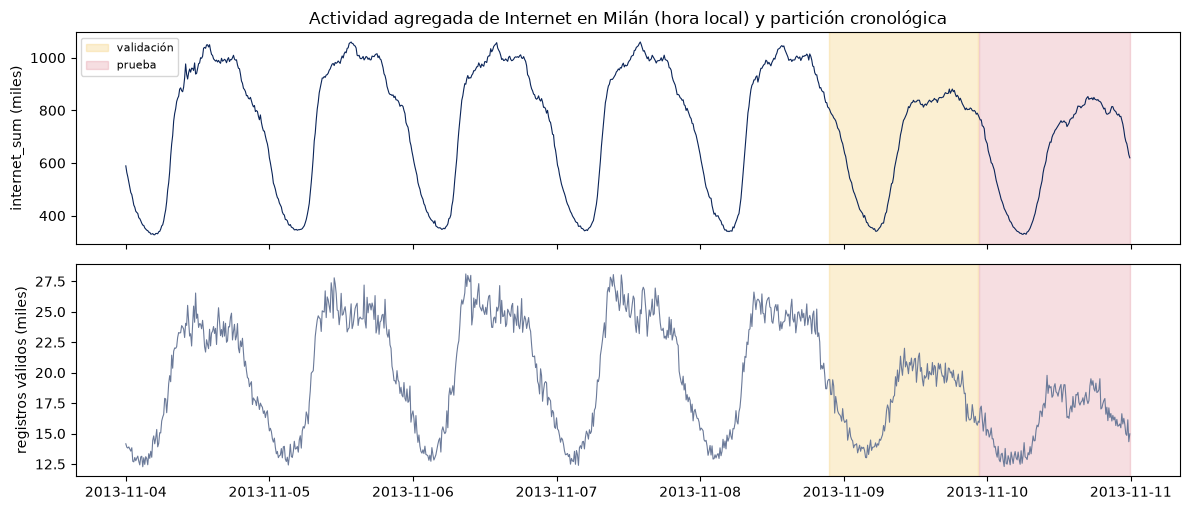

In [4]:
fig, ax = plt.subplots(2, 1, figsize=(12, 5.2), sharex=True)
ax[0].plot(df.ts_local, y / 1e3, lw=.8, color="#0b2559")
ax[1].plot(df.ts_local, df.observations / 1e3, lw=.8, color="#6b7a99")
for a in ax:
    a.axvspan(df.ts_local.iloc[CORTE1], df.ts_local.iloc[CORTE2 - 1], color="#f2c14e", alpha=.25, label="validación")
    a.axvspan(df.ts_local.iloc[CORTE2], df.ts_local.iloc[-1], color="#d1495b", alpha=.18, label="prueba")
ax[0].set_ylabel("internet_sum (miles)"); ax[1].set_ylabel("registros válidos (miles)")
ax[0].set_title("Actividad agregada de Internet en Milán (hora local) y partición cronológica")
ax[0].legend(loc="upper left", fontsize=8); plt.tight_layout()
plt.savefig(SAL / "fig1_serie_particion.png", dpi=150); plt.show()

**Lectura:**
- La serie tiene un ciclo diario claro: cerca de 330 mil en la madrugada y hasta 1,06 millones en el día; la mediana es 806 mil.
- El cambio entre intervalos es pequeño frente al nivel (mediana de 8.462) y tiene autocorrelación de 0,67 en el rezago 1: cuando la actividad sube, suele seguir subiendo. La persistencia no aprovecha esa inercia.
- Con la partición cronológica, el entrenamiento va de lunes a viernes, la validación es casi todo el sábado y la prueba es el domingo. El modelo se evalúa en días que no vio al entrenar: el nivel medio es 771 mil en entrenamiento, 680 mil en validación y 642 mil en prueba.
- La actividad sigue a la cobertura (r = 0,88), así que el índice también depende de cuántos registros válidos hay en cada intervalo.

## 3. Líneas base sobre las mismas ventanas
- **Persistencia**: ŷ<sub>t</sub> = y<sub>t-1</sub> (línea base del avance).
- **Deriva**: ŷ<sub>t</sub> = y<sub>t-1</sub> + (y<sub>t-1</sub> − y<sub>t-2</sub>); extrapola el último cambio. Es un rival ingenuo más exigente.
- **Media de ventana**: promedio de las 12 observaciones previas.
- **Ingenuo diario**: ŷ<sub>t</sub> = y<sub>t-144</sub> (mismo instante del día anterior).
- **Ridge (cambio)**: modelo lineal con las mismas entradas y el mismo objetivo que la red final; separa lo que aporta la formulación de lo que aporta la red. α se elige en validación.

In [5]:
def metricas(yv, yp):
    e = yv - yp
    return {"MAE": float(np.mean(np.abs(e))), "RMSE": float(np.sqrt(np.mean(e ** 2))),
            "MAPE_%": float(100 * np.mean(np.abs(e) / yv)), "sesgo": float(np.mean(e))}

PRED_BASE = {"Persistencia": y_prev,
             "Deriva": y_prev + (y_prev - y[idx - 2]),
             "Media de ventana": np.array([y[t - LOOKBACK:t].mean() for t in idx]),
             "Ingenuo diario": y[idx - 144] if idx.min() >= 144 else np.r_[np.full(144 - idx.min(), np.nan), y[idx[idx >= 144] - 144]]}
Xr = ENTRADAS["nivel+cambio+hora"].reshape(len(idx), -1)
ridge_val = {}
for a in [0.1, 1, 10, 100]:
    r = Ridge(alpha=a).fit(Xr[m_tr], OBJETIVOS["cambio"][m_tr])
    ridge_val[a] = metricas(y_obj[m_va], a_nivel(r.predict(Xr), "cambio")[m_va])["MAE"]
ALFA = min(ridge_val, key=ridge_val.get)
ridge = Ridge(alpha=ALFA).fit(Xr[m_tr], OBJETIVOS["cambio"][m_tr])
PRED_BASE["Ridge (cambio)"] = a_nivel(ridge.predict(Xr), "cambio")
print("MAE de validación de Ridge por α:", {k: round(v) for k, v in ridge_val.items()}, "| α elegido:", ALFA)

tabla_base_val = pd.DataFrame({k: metricas(y_obj[m_va], v[m_va]) for k, v in PRED_BASE.items()}).T
print("Líneas base en VALIDACIÓN (la prueba se usa solo en la sección 9):")
display(tabla_base_val.round(1))
MAE_PERS_VAL = tabla_base_val.loc["Persistencia", "MAE"]
MAE_DERIVA_VAL = tabla_base_val.loc["Deriva", "MAE"]

MAE de validación de Ridge por α: {0.1: 6426, 1: 6416, 10: 6326, 100: 5875} | α elegido: 100
Líneas base en VALIDACIÓN (la prueba se usa solo en la sección 9):


,MAE,RMSE,MAPE_%,sesgo
Persistencia,9146.6,11434.8,1.5,-203.7
Deriva,7611.7,9860.4,1.2,61.3
Media de ventana,48485.4,62552.7,8.3,-2535.2
Ingenuo diario,100812.8,131937.2,14.5,-88988.8
Ridge (cambio),5874.6,7646.1,0.9,-2242.4


**Lectura:**
- La persistencia ya es una buena referencia (MAPE de 1,5 %), porque en 10 minutos la serie cambia poco. La media de ventana y el ingenuo diario fallan: la primera reacciona tarde a las subidas y bajadas, y el segundo compara el sábado con el viernes.
- La deriva baja el MAE de validación de 9.147 a 7.612 (16,8 % menos) solo con repetir el último cambio. Es una primera señal de que conviene modelar el cambio y no el nivel.
- Ridge, con el objetivo de cambio y las mismas entradas de la red, llega a 5.875 con la regularización más fuerte (α = 100). Es el modelo lineal que la red debe superar para justificar su costo.

## 4. Arquitectura y bucle de entrenamiento
Capas: `Input(12, c)`, `LSTM` o `GRU` de 32 unidades, `Dropout(p)` y `Dense(1)` lineal.
- **Entrada (12, c)**: 2 horas de contexto; c = 1 (nivel) o 4 (nivel, cambio, seno y coseno de la hora local).
- **Capa recurrente de 32 unidades**: resume la ventana en un estado oculto. La LSTM usa compuertas de entrada, olvido y salida; la GRU usa actualización y reinicio con 25 % menos parámetros. Con 693 ventanas de entrenamiento, 32 unidades mantienen unos 4-5 mil parámetros (≈ 7 por ejemplo).
- **Dropout(p)**: regularización sobre el estado final; p se ajusta en la ronda 3.
- **Dense(1) lineal**: salida de regresión sin acotar; el cambio puede ser positivo o negativo.
- **Pérdida MSE** (la que optimiza la red) y **MAE** como métrica (la del informe, en las unidades de la serie).
- Presupuesto común: hasta 150 épocas, lote 32, `EarlyStopping(paciencia 15, restaura los mejores pesos)` y `ReduceLROnPlateau(×0,5, paciencia 6)`, ambos sobre la pérdida de validación.

In [6]:
def construir(tipo="GRU", canales=4, lr=1e-3, dropout=0.2, optimizador="adam", unidades=32):
    tf.keras.backend.clear_session()
    capa = tf.keras.layers.LSTM if tipo == "LSTM" else tf.keras.layers.GRU
    modelo = tf.keras.Sequential([
        tf.keras.layers.Input((LOOKBACK, canales)),
        capa(unidades, name=tipo.lower()),
        tf.keras.layers.Dropout(dropout),
        tf.keras.layers.Dense(1, name="salida")])
    opt = {"adam": tf.keras.optimizers.Adam, "rmsprop": tf.keras.optimizers.RMSprop}[optimizador](learning_rate=lr)
    modelo.compile(optimizer=opt, loss="mse", metrics=["mae"])
    return modelo

for t in ["LSTM", "GRU"]:
    for c in [1, 4]:
        print(f"{t} con {c} canal(es): {construir(t, c).count_params():,} parámetros")
construir("GRU", 4).summary()

LSTM con 1 canal(es): 4,385 parámetros
LSTM con 4 canal(es): 4,769 parámetros


GRU con 1 canal(es): 3,393 parámetros
GRU con 4 canal(es): 3,681 parámetros


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ gru (GRU)                       │ (None, 32)             │         3,648 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ salida (Dense)                  │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,681 (14.38 KB)

 Trainable params: 3,681 (14.38 KB)

 Non-trainable params: 0 (0.00 B)

In [7]:
if USAR_MLFLOW:
    mlflow.set_tracking_uri((RAIZ / "mlruns").as_uri())
    mlflow.set_experiment("U4_Milan_pronostico_10min")
REGISTRO, HIST, PRED = [], {}, {}

def entrenar(nombre, ronda, tipo, entrada, objetivo, lr=1e-3, dropout=0.2, optimizador="adam"):
    """Entrena una configuración con las 3 semillas; guarda historia, predicción y métricas de validación."""
    X, Y = ENTRADAS[entrada], OBJETIVOS[objetivo]
    for s in SEMILLAS:
        fijar_semilla(s)
        modelo = construir(tipo, X.shape[-1], lr, dropout, optimizador)
        cb = [tf.keras.callbacks.EarlyStopping(monitor="val_loss", patience=PACIENCIA_ES, restore_best_weights=True),
              tf.keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=PACIENCIA_LR, min_lr=1e-5)]
        t0 = time.time()
        h = modelo.fit(X[m_tr], Y[m_tr], validation_data=(X[m_va], Y[m_va]), epochs=EPOCAS_MAX,
                       batch_size=LOTE, shuffle=True, callbacks=cb, verbose=0)
        seg = time.time() - t0
        p = a_nivel(modelo.predict(X, verbose=0, batch_size=512).ravel(), objetivo)
        mv = metricas(y_obj[m_va], p[m_va])
        mejor_ep = int(np.argmin(h.history["val_loss"])) + 1
        fila = {"nombre": nombre, "ronda": ronda, "tipo": tipo, "entrada": entrada, "objetivo": objetivo,
                "lr": lr, "dropout": dropout, "optimizador": optimizador, "semilla": s,
                "parametros": modelo.count_params(), "epocas": len(h.history["loss"]), "mejor_epoca": mejor_ep,
                "val_MAE": mv["MAE"], "val_RMSE": mv["RMSE"], "segundos": seg}
        REGISTRO.append(fila); HIST[(nombre, s)] = h.history; PRED[(nombre, s)] = p
        if USAR_MLFLOW:
            with mlflow.start_run(run_name=f"{nombre}_s{s}"):
                mlflow.set_tags({"ronda": ronda, "conjunto_prueba": "no usado"})
                mlflow.log_params({k: fila[k] for k in ["tipo", "entrada", "objetivo", "lr", "dropout", "optimizador",
                                                        "semilla", "parametros"]} |
                                  {"lookback": LOOKBACK, "lote": LOTE, "epocas_max": EPOCAS_MAX, "corte1": CORTE1, "corte2": CORTE2})
                mlflow.log_metrics({k: fila[k] for k in ["val_MAE", "val_RMSE", "epocas", "mejor_epoca", "segundos"]})
                for ep, (a, b) in enumerate(zip(h.history["loss"], h.history["val_loss"])):
                    mlflow.log_metrics({"loss": a, "val_loss": b}, step=ep)
        yield modelo

def correr(*a, **k):
    for _ in entrenar(*a, **k):
        pass

def ver(t, n=None):
    """Tabla legible: lr con su valor real y métricas redondeadas."""
    t = (t.head(n) if n else t).copy()
    t["lr"] = t["lr"].map("{:g}".format)
    return t.round(1)

def resumen(ronda=None):
    r = pd.DataFrame(REGISTRO)
    if ronda is not None:
        r = r[r.ronda.isin([ronda] if isinstance(ronda, str) else ronda)]
    g = r.groupby("nombre", sort=False).agg(tipo=("tipo", "first"), entrada=("entrada", "first"), objetivo=("objetivo", "first"),
        lr=("lr", "first"), dropout=("dropout", "first"), optimizador=("optimizador", "first"),
        val_MAE=("val_MAE", "mean"), val_MAE_DE=("val_MAE", "std"), epocas=("epocas", "mean"),
        mejor_epoca=("mejor_epoca", "mean"), segundos=("segundos", "mean"))
    g["vs_persistencia_%"] = 100 * (g.val_MAE / MAE_PERS_VAL - 1)
    return g.sort_values("val_MAE")

## 5. Ronda 1 · Reproducción del avance (objetivo = nivel, entrada = nivel)
Los cinco experimentos del avance bajo el protocolo común (3 semillas, mismo presupuesto). E1 es la referencia; E2 cambia solo la tasa de aprendizaje, E3 solo el *dropout*, E4 solo la celda y E5 solo el optimizador.

In [8]:
R1 = [("E1_LSTM_base", "LSTM", 1e-3, .2, "adam"), ("E2_LSTM_lr", "LSTM", 5e-4, .2, "adam"),
      ("E3_LSTM_dropout", "LSTM", 1e-3, .3, "adam"), ("E4_GRU", "GRU", 1e-3, .2, "adam"),
      ("E5_LSTM_rmsprop", "LSTM", 1e-3, .2, "rmsprop")]
t0 = time.time()
for n, t, lr, p, o in R1:
    correr(n, "R1", t, "nivel", "nivel", lr, p, o)
print(f"Ronda 1: {len(R1) * 3} entrenamientos en {time.time() - t0:.0f} s")
r1 = resumen("R1"); display(ver(r1))

Ronda 1: 15 entrenamientos en 40 s


,tipo,entrada,objetivo,lr,dropout,optimizador,val_MAE,val_MAE_DE,epocas,mejor_epoca,segundos,vs_persistencia_%
nombre,,,,,,,,,,,,
E4_GRU,GRU,nivel,nivel,0.001,0.2,adam,6726.6,739.6,53.3,38.3,2.9,-26.5
E5_LSTM_rmsprop,LSTM,nivel,nivel,0.001,0.2,rmsprop,7484.3,581.1,51.3,36.3,2.5,-18.2
E3_LSTM_dropout,LSTM,nivel,nivel,0.001,0.3,adam,10669.4,730.0,45.3,30.3,2.4,16.6
E1_LSTM_base,LSTM,nivel,nivel,0.001,0.2,adam,10703.0,1681.8,33.0,18.0,2.0,17.0
E2_LSTM_lr,LSTM,nivel,nivel,0.0005,0.2,adam,12193.8,1209.2,42.3,27.3,2.3,33.3


### Diagnóstico de la ronda 1 en validación: ¿la red copia el último valor?

In [9]:
mejor_r1 = r1.index[0]
p1 = np.mean([PRED[(mejor_r1, s)] for s in SEMILLAS], axis=0)
mae_vs_actual = np.mean(np.abs(p1[m_va] - y_obj[m_va]))
mae_vs_previo = np.mean(np.abs(p1[m_va] - y_prev[m_va]))
corr_cambio = np.corrcoef(p1[m_va] - y_prev[m_va], y_obj[m_va] - y_prev[m_va])[0, 1]
print(f"{mejor_r1}: distancia media al valor real {mae_vs_actual:,.0f} vs. al último valor observado {mae_vs_previo:,.0f}")
print(f"Correlación entre el cambio implícito de la red y el cambio real: {corr_cambio:.3f}")
print(f"Desviación estándar del nivel en entrenamiento: {sc_y.scale_[0]:,.0f}; del cambio: {sc_d.scale_[0]:,.0f} "
      f"(el cambio es {sc_y.scale_[0] / sc_d.scale_[0]:.0f} veces más pequeño que el nivel)")

E4_GRU: distancia media al valor real 6,493 vs. al último valor observado 9,565
Correlación entre el cambio implícito de la red y el cambio real: 0.768
Desviación estándar del nivel en entrenamiento: 251,097; del cambio: 16,524 (el cambio es 15 veces más pequeño que el nivel)


**Lectura:**
- La mejor red de la ronda 1 (E4, GRU) mejora a la persistencia en validación (6.727 frente a 9.147, es decir, 26,5 % menos). Sin embargo, tres de las cinco configuraciones del avance quedan peor que la persistencia (E1, E2 y E3), y la desviación entre semillas llega a 1.682.
- Con el objetivo de nivel, la red tiene que reproducir un valor de unos 800 mil para acertar un cambio de unos 8 mil, y la desviación del cambio es 15 veces menor que la del nivel. Cualquier error en el nivel, incluido el ruido que mete el *dropout* en el estado oculto, pesa más que el cambio.
- Por eso, en la ronda 2 la red predice el cambio, y el pronóstico es el último valor más el cambio previsto. La persistencia queda como el caso en que la red predice un cambio de cero.

## 6. Ronda 2 · Formulación del objetivo y entradas
Diseño factorial 2 × 2 × 2 con los hiperparámetros por defecto (Adam, lr = 0,001, *dropout* = 0,2): celda {LSTM, GRU} × objetivo {nivel, cambio} × entrada {nivel, nivel+cambio+hora}. Así se separa el efecto de cada factor.

In [10]:
t0 = time.time()
for t in ["LSTM", "GRU"]:
    for obj in ["nivel", "cambio"]:
        for ent in ["nivel", "nivel+cambio+hora"]:
            correr(f"R2_{t}_{obj}_{ent}", "R2", t, ent, obj)
print(f"Ronda 2: 24 entrenamientos en {time.time() - t0:.0f} s")
r2 = resumen("R2"); display(ver(r2))

Ronda 2: 24 entrenamientos en 65 s


,tipo,entrada,objetivo,lr,dropout,optimizador,val_MAE,val_MAE_DE,epocas,mejor_epoca,segundos,vs_persistencia_%
nombre,,,,,,,,,,,,
R2_GRU_cambio_nivel+cambio+hora,GRU,nivel+cambio+hora,cambio,0.001,0.2,adam,5844.1,298.5,18.3,3.3,1.6,-36.1
R2_LSTM_cambio_nivel+cambio+hora,LSTM,nivel+cambio+hora,cambio,0.001,0.2,adam,6188.8,306.6,16.7,1.7,1.4,-32.3
R2_GRU_cambio_nivel,GRU,nivel,cambio,0.001,0.2,adam,6365.9,51.3,63.3,48.3,3.4,-30.4
R2_LSTM_cambio_nivel,LSTM,nivel,cambio,0.001,0.2,adam,6453.0,120.4,56.3,41.3,2.8,-29.5
R2_GRU_nivel_nivel,GRU,nivel,nivel,0.001,0.2,adam,6726.6,739.6,53.3,38.3,2.9,-26.5
R2_LSTM_nivel_nivel,LSTM,nivel,nivel,0.001,0.2,adam,10703.0,1681.8,33.0,18.0,2.0,17.0
R2_GRU_nivel_nivel+cambio+hora,GRU,nivel+cambio+hora,nivel,0.001,0.2,adam,30153.2,10887.9,70.3,55.3,3.6,229.7
R2_LSTM_nivel_nivel+cambio+hora,LSTM,nivel+cambio+hora,nivel,0.001,0.2,adam,45191.8,7441.9,22.3,7.3,1.6,394.1


**Lectura:**
- Predecir el cambio en lugar del nivel mejora todas las combinaciones. Con una sola entrada, la GRU pasa de 6.727 a 6.366 y la LSTM de 10.703 a 6.453, y la desviación entre semillas baja de 740-1.682 a 51-120.
- La hora del día y el cambio pasado ayudan **solo** cuando el objetivo es el cambio (la GRU pasa de 6.366 a 5.844). Con el objetivo de nivel empeoran mucho (30.153 y 45.192), porque la red aprende el perfil de lunes a viernes y lo aplica a un sábado con otro nivel.
- La GRU supera a la LSTM en las cuatro combinaciones, con 23 % menos parámetros (3.681 frente a 4.769).
- La mejor combinación (GRU, objetivo de cambio, entradas de nivel, cambio y hora) ya mejora en validación a la persistencia en 36,1 % y a la deriva en 23,2 %.

## 7. Ronda 3 · Búsqueda sistemática de hiperparámetros
Siguiendo el *tuning playbook* de Google, la celda (LSTM vs. GRU) es el hiperparámetro **científico** y la tasa de aprendizaje, el *dropout* y el optimizador son **de ruido**: se optimizan por separado para cada celda antes de compararlas. Malla completa: lr {0,0003; 0,001; 0,003} × *dropout* {0; 0,2; 0,4} × optimizador {Adam, RMSprop} × celda {LSTM, GRU} = 36 configuraciones × 3 semillas = 108 entrenamientos, todos con objetivo = cambio y entrada = nivel+cambio+hora.

In [11]:
t0 = time.time()
for t in ["LSTM", "GRU"]:
    for o in ["adam", "rmsprop"]:
        for lr in [3e-4, 1e-3, 3e-3]:
            for p in [0.0, 0.2, 0.4]:
                correr(f"R3_{t}_{o}_lr{lr:g}_do{p:g}", "R3", t, "nivel+cambio+hora", "cambio", lr, p, o)
print(f"Ronda 3: 108 entrenamientos en {time.time() - t0:.0f} s")
r3 = resumen("R3")
display(ver(r3, 10))
print("Mejor configuración por celda (validación):")
display(ver(r3.groupby("tipo").head(1)))

Ronda 3: 108 entrenamientos en 211 s


,tipo,entrada,objetivo,lr,dropout,optimizador,val_MAE,val_MAE_DE,epocas,mejor_epoca,segundos,vs_persistencia_%
nombre,,,,,,,,,,,,
R3_GRU_adam_lr0.003_do0.4,GRU,nivel+cambio+hora,cambio,0.003,0.4,adam,5652.9,147.5,17.0,2.0,1.6,-38.2
R3_GRU_adam_lr0.001_do0.4,GRU,nivel+cambio+hora,cambio,0.001,0.4,adam,5741.3,158.3,19.3,4.3,1.7,-37.2
R3_GRU_adam_lr0.0003_do0.4,GRU,nivel+cambio+hora,cambio,0.0003,0.4,adam,5744.1,193.5,24.0,9.0,1.9,-37.2
R3_GRU_rmsprop_lr0.0003_do0.4,GRU,nivel+cambio+hora,cambio,0.0003,0.4,rmsprop,5753.4,183.4,28.0,13.0,1.9,-37.1
R3_GRU_adam_lr0.003_do0.2,GRU,nivel+cambio+hora,cambio,0.003,0.2,adam,5759.6,260.2,17.0,2.0,1.6,-37.0
R3_LSTM_adam_lr0.0003_do0,LSTM,nivel+cambio+hora,cambio,0.0003,0.0,adam,5779.6,279.7,19.0,4.0,1.4,-36.8
R3_LSTM_rmsprop_lr0.0003_do0,LSTM,nivel+cambio+hora,cambio,0.0003,0.0,rmsprop,5790.2,262.0,18.3,3.3,1.3,-36.7
R3_GRU_adam_lr0.0003_do0.2,GRU,nivel+cambio+hora,cambio,0.0003,0.2,adam,5800.7,223.4,23.7,8.7,1.9,-36.6
R3_GRU_rmsprop_lr0.0003_do0.2,GRU,nivel+cambio+hora,cambio,0.0003,0.2,rmsprop,5819.8,197.7,23.0,8.0,1.7,-36.4


Mejor configuración por celda (validación):


,tipo,entrada,objetivo,lr,dropout,optimizador,val_MAE,val_MAE_DE,epocas,mejor_epoca,segundos,vs_persistencia_%
nombre,,,,,,,,,,,,
R3_GRU_adam_lr0.003_do0.4,GRU,nivel+cambio+hora,cambio,0.003,0.4,adam,5652.9,147.5,17.0,2.0,1.6,-38.2
R3_LSTM_adam_lr0.0003_do0,LSTM,nivel+cambio+hora,cambio,0.0003,0.0,adam,5779.6,279.7,19.0,4.0,1.4,-36.8


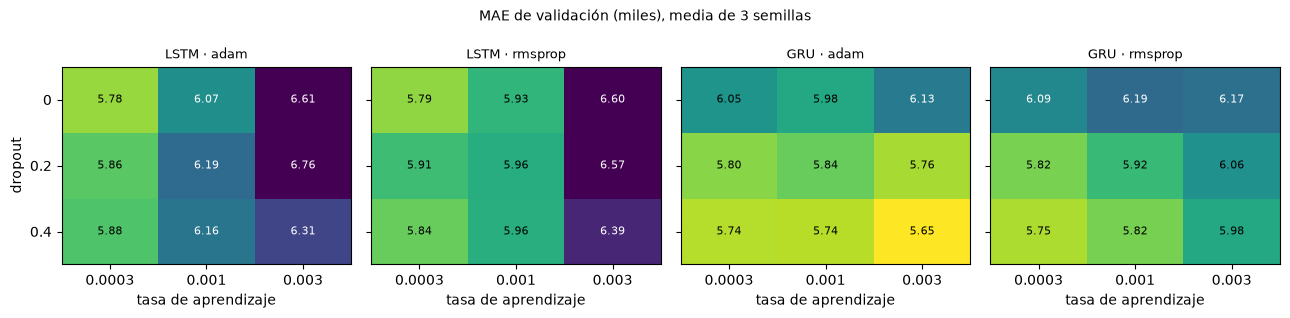

Efecto marginal en la ronda 3 (MAE de validación medio):


  tipo: {'GRU': 5918.0, 'LSTM': 6143.0}
  optimizador: {'adam': 6018.0, 'rmsprop': 6043.0}
  lr: {0.0003: 5861.0, 0.001: 5981.0, 0.003: 6249.0}
  dropout: {0.0: 6117.0, 0.2: 6038.0, 0.4: 5937.0}


In [12]:
fig, axs = plt.subplots(1, 4, figsize=(13, 3.2), sharey=True)
vmin, vmax = r3.val_MAE.min(), r3.val_MAE.quantile(.9)
for ax, (t, o) in zip(axs, [(t, o) for t in ["LSTM", "GRU"] for o in ["adam", "rmsprop"]]):
    sub = r3[(r3.tipo == t) & (r3.optimizador == o)].pivot_table(index="dropout", columns="lr", values="val_MAE")
    im = ax.imshow(sub.values, cmap="viridis_r", vmin=vmin, vmax=vmax, aspect="auto")
    for i in range(sub.shape[0]):
        for j in range(sub.shape[1]):
            ax.text(j, i, f"{sub.values[i, j] / 1e3:.2f}", ha="center", va="center", fontsize=8,
                    color="white" if sub.values[i, j] > (vmin + vmax) / 2 else "black")
    ax.set_xticks(range(3), [f"{c:g}" for c in sub.columns]); ax.set_yticks(range(3), [f"{c:g}" for c in sub.index])
    ax.set_title(f"{t} · {o}", fontsize=9); ax.set_xlabel("tasa de aprendizaje")
axs[0].set_ylabel("dropout")
fig.suptitle("MAE de validación (miles), media de 3 semillas", fontsize=10)
plt.tight_layout(); plt.savefig(SAL / "fig3_malla_hiperparametros.png", dpi=150); plt.show()

tab = pd.DataFrame(REGISTRO); tab.to_csv(SAL / "experimentos.csv", index=False)
efecto = {f: tab[tab.ronda == "R3"].groupby(f).val_MAE.mean().round(0).to_dict() for f in ["tipo", "optimizador", "lr", "dropout"]}
print("Efecto marginal en la ronda 3 (MAE de validación medio):")
for f, v in efecto.items():
    print(f"  {f}: {v}")

**Lectura:**
- La tasa de aprendizaje es el hiperparámetro con más efecto: el MAE medio sube de 5.861 con 0,0003 a 6.249 con 0,003. La GRU tolera la tasa alta: con *dropout* de 0,4 obtiene el mejor resultado de la malla.
- El error baja a medida que sube el *dropout* (0: 6.117; 0,2: 6.038; 0,4: 5.937), igual que Ridge prefirió el α más alto. Con 693 ventanas, el riesgo es el sobreajuste, no la falta de capacidad.
- Adam y RMSprop dan resultados casi iguales (6.018 frente a 6.043). Con el objetivo de cambio, el optimizador deja de ser decisivo; en la ronda 1 sí lo era.
- Con su mejor configuración, la GRU obtiene 5.653 ± 148 y la LSTM 5.780 ± 280. Las cinco mejores configuraciones están dentro de una desviación estándar entre semillas (5.653-5.760), así que lo que se mantiene es la combinación GRU, *dropout* 0,4 y objetivo de cambio.

### Selección final (solo validación)

In [13]:
SEL = r3.index[0]
cfg = r3.loc[SEL]
p_sem = np.array([PRED[(SEL, s)] for s in SEMILLAS])
p_ens = p_sem.mean(axis=0)
mae_ind_val = [metricas(y_obj[m_va], p[m_va])["MAE"] for p in p_sem]
mae_ens_val = metricas(y_obj[m_va], p_ens[m_va])["MAE"]
print(f"Seleccionada: {SEL} ({cfg.tipo}, {cfg.optimizador}, lr={cfg.lr:g}, dropout={cfg.dropout:g})")
print(f"Validación: MAE por semilla {np.round(mae_ind_val, 0)} | media {np.mean(mae_ind_val):,.0f} | "
      f"promedio de las 3 semillas (ensamble) {mae_ens_val:,.0f}")
USAR_ENSAMBLE = mae_ens_val < np.mean(mae_ind_val)
print("Decisión en validación:", "usar el promedio de las 3 semillas" if USAR_ENSAMBLE else "usar modelos individuales")
mejor_lstm = r3[r3.tipo == "LSTM"].index[0]; mejor_gru = r3[r3.tipo == "GRU"].index[0]

Seleccionada: R3_GRU_adam_lr0.003_do0.4 (GRU, adam, lr=0.003, dropout=0.4)
Validación: MAE por semilla [5541. 5597. 5820.] | media 5,653 | promedio de las 3 semillas (ensamble) 5,599
Decisión en validación: usar el promedio de las 3 semillas


**Lectura:**
- La regla fijada antes de entrenar (menor MAE medio de validación) elige GRU, Adam, lr = 0,003 y *dropout* = 0,4.
- El promedio de las tres semillas baja el MAE de validación de 5.653 a 5.599, así que, también con base en validación, usamos ese promedio como modelo final. Cuesta tres inferencias de un modelo de 3.681 parámetros.

## 8. Curvas de aprendizaje
Pérdida (MSE escalado) y MAE en unidades originales por época, entrenamiento vs. validación, para las tres semillas. La tercera columna repite la configuración elegida con una tasa de aprendizaje 10 veces menor, solo como diagnóstico. El MAE escalado se multiplica por la desviación estándar del objetivo, así que la línea punteada de persistencia es directamente comparable. El MAE de entrenamiento que reporta Keras se mide con *dropout* activo.

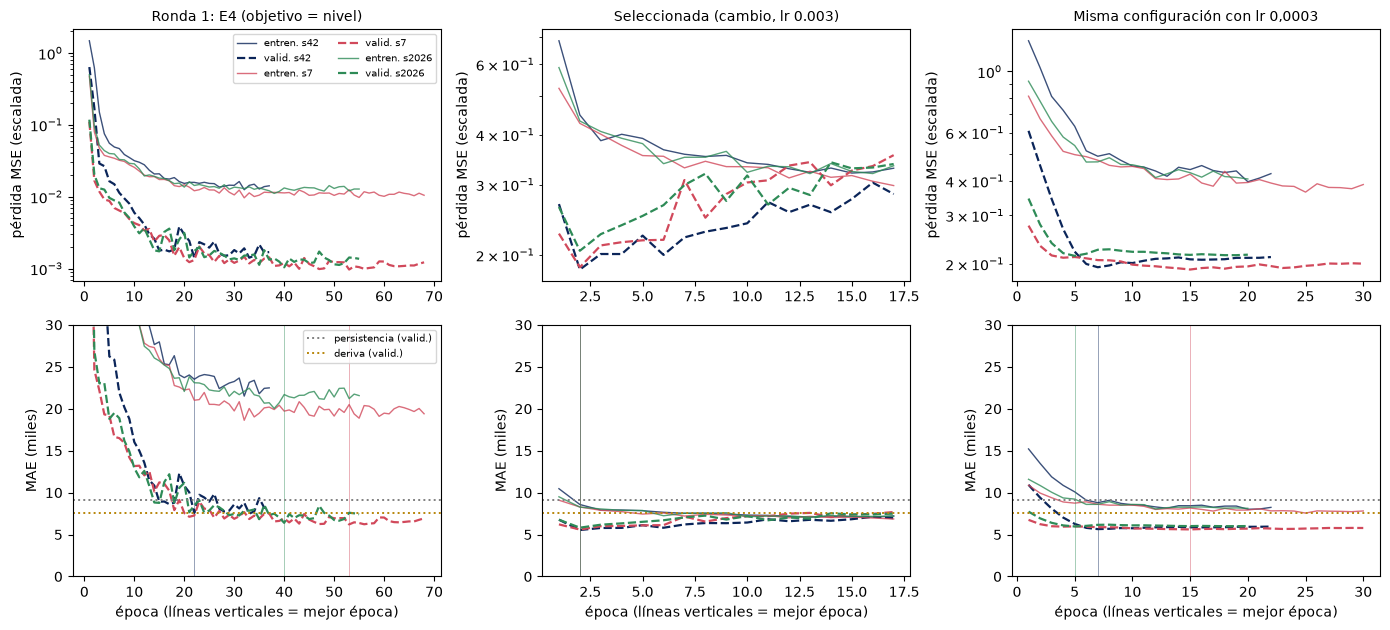

E4_GRU                       s42    épocas  37 | mejor  22 | pérdida entren./valid. en la mejor época 0.016 / 0.001 (cociente 0.09) | lr final 1.3e-04
E4_GRU                       s7     épocas  68 | mejor  53 | pérdida entren./valid. en la mejor época 0.012 / 0.001 (cociente 0.08) | lr final 1.6e-05
E4_GRU                       s2026  épocas  55 | mejor  40 | pérdida entren./valid. en la mejor época 0.013 / 0.001 (cociente 0.08) | lr final 3.1e-05
R3_GRU_adam_lr0.003_do0.4    s42    épocas  17 | mejor   2 | pérdida entren./valid. en la mejor época 0.448 / 0.184 (cociente 0.41) | lr final 7.5e-04
R3_GRU_adam_lr0.003_do0.4    s7     épocas  17 | mejor   2 | pérdida entren./valid. en la mejor época 0.427 / 0.186 (cociente 0.44) | lr final 7.5e-04
R3_GRU_adam_lr0.003_do0.4    s2026  épocas  17 | mejor   2 | pérdida entren./valid. en la mejor época 0.433 / 0.205 (cociente 0.47) | lr final 7.5e-04
R3_GRU_adam_lr0.0003_do0.4   s42    épocas  22 | mejor   7 | pérdida entren./valid. en la mejo

,MAE entren.,R² cambio entren.,MAE valid.,R² cambio valid.
config,,,,
E4_GRU,10466.507,0.301,6726.621,0.449
R3_GRU_adam_lr0.003_do0.4,7537.212,0.639,5652.913,0.600
R3_GRU_adam_lr0.0003_do0.4,7930.659,0.597,5744.136,0.583


In [14]:
def escala(nombre):
    return sc_y.scale_[0] if pd.DataFrame(REGISTRO).query("nombre == @nombre").objetivo.iloc[0] == "nivel" else sc_d.scale_[0]

LENTA = f"R3_{cfg.tipo}_{cfg.optimizador}_lr0.0003_do{cfg.dropout:g}"
casos = [(mejor_r1, "Ronda 1: E4 (objetivo = nivel)"), (SEL, f"Seleccionada (cambio, lr {cfg.lr:g})"),
         (LENTA, "Misma configuración con lr 0,0003")]
fig, axs = plt.subplots(2, 3, figsize=(14, 6.4))
colores = {42: "#0b2559", 7: "#d1495b", 2026: "#2e8b57"}
for j, (nom, tit) in enumerate(casos):
    k = escala(nom)
    for s in SEMILLAS:
        h = HIST[(nom, s)]; ep = np.arange(1, len(h["loss"]) + 1)
        axs[0, j].plot(ep, h["loss"], color=colores[s], lw=1, alpha=.8, label=f"entren. s{s}")
        axs[0, j].plot(ep, h["val_loss"], color=colores[s], lw=1.6, ls="--", label=f"valid. s{s}")
        axs[1, j].plot(ep, np.array(h["mae"]) * k / 1e3, color=colores[s], lw=1, alpha=.8)
        axs[1, j].plot(ep, np.array(h["val_mae"]) * k / 1e3, color=colores[s], lw=1.6, ls="--")
        mb = int(np.argmin(h["val_loss"])) + 1
        axs[1, j].axvline(mb, color=colores[s], lw=.6, alpha=.5)
    axs[1, j].axhline(MAE_PERS_VAL / 1e3, color="gray", ls=":", lw=1.4, label="persistencia (valid.)")
    axs[1, j].axhline(MAE_DERIVA_VAL / 1e3, color="#b8860b", ls=":", lw=1.4, label="deriva (valid.)")
    axs[0, j].set_title(tit, fontsize=10); axs[0, j].set_ylabel("pérdida MSE (escalada)"); axs[0, j].set_yscale("log")
    axs[1, j].set_ylabel("MAE (miles)"); axs[1, j].set_xlabel("época (líneas verticales = mejor época)")
    axs[1, j].set_ylim(0, max(30, MAE_PERS_VAL / 1e3 * 2.2))
axs[0, 0].legend(fontsize=7, ncol=2); axs[1, 0].legend(fontsize=7)
plt.tight_layout(); plt.savefig(SAL / "fig2_curvas_aprendizaje.png", dpi=150); plt.show()

for nom, _ in casos:
    for s in SEMILLAS:
        h = HIST[(nom, s)]; mb = int(np.argmin(h["val_loss"]))
        print(f"{nom:28s} s{s:<5d} épocas {len(h['loss']):3d} | mejor {mb + 1:3d} | "
              f"pérdida entren./valid. en la mejor época {h['loss'][mb]:.3f} / {h['val_loss'][mb]:.3f} "
              f"(cociente {h['val_loss'][mb] / h['loss'][mb]:.2f}) | lr final {h.get('learning_rate', [np.nan])[-1]:.1e}")

# Diagnóstico sin dropout: error de los pesos restaurados en cada partición, en unidades originales
d_real = y_obj - y_prev
print(f"\nDesviación estándar del cambio real: entrenamiento {d_real[m_tr].std():,.0f} | validación {d_real[m_va].std():,.0f} "
      f"| cociente de varianzas {d_real[m_va].var() / d_real[m_tr].var():.2f}")
filas = []
for nom, _ in casos:
    for s in SEMILLAS:
        p = PRED[(nom, s)]
        f = {"config": nom, "semilla": s}
        for parte, m in [("entren.", m_tr), ("valid.", m_va)]:
            e = d_real[m] - (p[m] - y_prev[m])
            f[f"MAE {parte}"] = np.mean(np.abs(e))
            f[f"R² cambio {parte}"] = 1 - np.sum(e ** 2) / np.sum((d_real[m] - d_real[m].mean()) ** 2)
        filas.append(f)
diag = pd.DataFrame(filas).groupby("config", sort=False).mean(numeric_only=True).drop(columns="semilla")
print("Pesos restaurados, sin dropout (media de 3 semillas):"); display(diag.round(3))

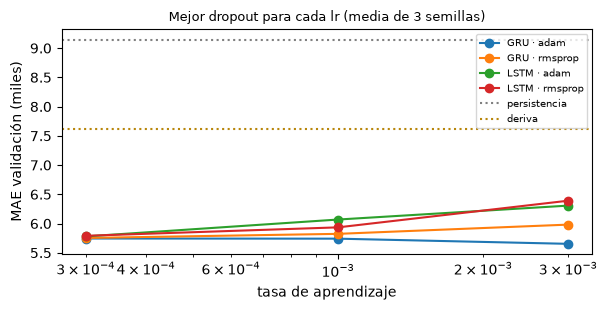

In [15]:
# Sensibilidad a la tasa de aprendizaje (ronda 3): MAE de validación medio por lr, celda y optimizador
fig, ax = plt.subplots(figsize=(6.2, 3.2))
for (t, o), g in r3.groupby(["tipo", "optimizador"]):
    m = g.groupby("lr").val_MAE.min()
    ax.plot(m.index, m.values / 1e3, marker="o", label=f"{t} · {o}")
ax.axhline(MAE_PERS_VAL / 1e3, color="gray", ls=":", label="persistencia")
ax.axhline(MAE_DERIVA_VAL / 1e3, color="#b8860b", ls=":", label="deriva")
ax.set_xscale("log"); ax.set_xlabel("tasa de aprendizaje"); ax.set_ylabel("MAE validación (miles)")
ax.set_title("Mejor dropout para cada lr (media de 3 semillas)", fontsize=9); ax.legend(fontsize=7)
plt.tight_layout(); plt.savefig(SAL / "fig4_sensibilidad_lr.png", dpi=150); plt.show()

**Lectura:**
- Con el objetivo de nivel (ronda 1), la pérdida de entrenamiento queda unas 12 veces por encima de la de validación (cociente 0,08-0,09). No es subajuste: el *dropout* altera el estado que representa un nivel de unos 800 mil, y ese ruido infla la pérdida de entrenamiento. La mejor época varía entre 22 y 53 según la semilla, y la tasa de aprendizaje termina entre 1,6e-05 y 1,3e-04 después de varias reducciones. Es un entrenamiento lento y poco estable.
- Con el objetivo de cambio (modelo seleccionado), la pérdida de validación llega a su mínimo en la época 2 con las tres semillas. Después baja la de entrenamiento y sube la de validación, que es el comienzo del sobreajuste. `EarlyStopping` recupera los pesos de la época 2 y se detiene en la 17.
- La pérdida de validación queda por debajo de la de entrenamiento (cociente 0,41-0,47) por dos razones: el *dropout* de 0,4 solo actúa al entrenar, y el sábado tiene cambios más pequeños (desviación de 11.433 frente a 16.505; la varianza es el 48 % de la de entrenamiento). Medido sin *dropout* con los pesos recuperados, el R² del cambio es 0,64 en entrenamiento y 0,60 en validación (tabla anterior), así que en la época elegida no hay sobreajuste. El MAE de entrenamiento es mayor (7.537 frente a 5.653) porque los días laborales tienen cambios más grandes. E4 explica mucho menos el cambio (R² de 0,30 y 0,45).
- Con lr = 0,0003 la curva es más suave y el mínimo llega entre las épocas 5 y 15, con un MAE de validación casi igual (5.744 frente a 5.653, dentro de una desviación estándar). La tasa alta converge antes y la baja es más estable; las dos son opciones equivalentes.
- En la curva de sensibilidad, todas las combinaciones de la ronda 3 quedan por debajo de la persistencia y de la deriva en validación.

## 9. Evaluación única en prueba
El avance ya había evaluado E5 en prueba (MAE 9.906). En esta versión todas las decisiones usan solo validación y la prueba se evalúa una vez, aquí, con la configuración ya fija. Comparamos sobre las **mismas 152 ventanas**. Para el contraste formal usamos la diferencia pareada del error absoluto d<sub>t</sub> = |e<sub>modelo</sub>| − |e<sub>base</sub>|:
- IC 95 % por *bootstrap* de bloques móviles (bloques de 12 pasos = 2 h, 5.000 réplicas), porque los errores están autocorrelacionados.
- Prueba de Diebold-Mariano con varianza de Newey-West (5 rezagos) y corrección de Harvey, Leybourne y Newbold.

In [16]:
from scipy import stats

def bootstrap_bloques(d, b=12, reps=5000, semilla=42):
    rng = np.random.default_rng(semilla); n = len(d); k = int(np.ceil(n / b))
    ini = rng.integers(0, n - b + 1, size=(reps, k))
    muestras = np.concatenate([d[i:i + b] for i in range(n - b + 1)]).reshape(-1, b)[ini].reshape(reps, -1)[:, :n]
    return np.percentile(muestras.mean(axis=1), [2.5, 97.5])

def diebold_mariano(d, rezagos=5):
    n = len(d); dc = d - d.mean()
    gamma = [np.sum(dc[k:] * dc[:n - k]) / n for k in range(rezagos + 1)]
    var = gamma[0] + 2 * sum((1 - k / (rezagos + 1)) * gamma[k] for k in range(1, rezagos + 1))
    dm = d.mean() / np.sqrt(var / n)
    dm *= np.sqrt((n + 1 - 2 + 0) / n)                     # corrección HLN para h = 1
    return dm, 2 * stats.t.sf(abs(dm), df=n - 1)

yt = y_obj[m_te]
P_FINAL = p_ens if USAR_ENSAMBLE else p_sem[0]
modelos_prueba = {**{k: v for k, v in PRED_BASE.items()},
                  f"Ronda 1: {mejor_r1}": np.mean([PRED[(mejor_r1, s)] for s in SEMILLAS], axis=0),
                  f"Mejor LSTM R3": np.mean([PRED[(mejor_lstm, s)] for s in SEMILLAS], axis=0),
                  "Seleccionada (final)": P_FINAL}
filas = []
for k, p in modelos_prueba.items():
    ok = ~np.isnan(p[m_te])
    f = {"modelo": k, **metricas(yt[ok], p[m_te][ok])}
    f["mejora_vs_persistencia_%"] = 100 * (1 - f["MAE"] / metricas(yt, PRED_BASE["Persistencia"][m_te])["MAE"])
    filas.append(f)
tabla_prueba = pd.DataFrame(filas).set_index("modelo")
por_semilla = [metricas(yt, p[m_te])["MAE"] for p in p_sem]
print(f"Seleccionada, MAE por semilla en prueba: {np.round(por_semilla, 0)} | media {np.mean(por_semilla):,.0f} ± {np.std(por_semilla, ddof=1):,.0f}")
display(tabla_prueba.round(1))
tabla_prueba.to_csv(SAL / "comparacion_prueba.csv")

contrastes = []
e_fin = np.abs(yt - P_FINAL[m_te])
for base in ["Persistencia", "Deriva", "Ridge (cambio)", f"Ronda 1: {mejor_r1}"]:
    d = e_fin - np.abs(yt - modelos_prueba[base][m_te])
    lo, hi = bootstrap_bloques(d)
    dm, pv = diebold_mariano(d)
    contrastes.append({"frente a": base, "ΔMAE": d.mean(), "IC95_inf": lo, "IC95_sup": hi,
                       "Δ_%": 100 * d.mean() / np.abs(yt - modelos_prueba[base][m_te]).mean(),
                       "DM": dm, "p_valor": pv, "gana_en_%_de_ventanas": 100 * np.mean(d < 0)})
tabla_contrastes = pd.DataFrame(contrastes).set_index("frente a")
display(tabla_contrastes.round({"ΔMAE": 0, "IC95_inf": 0, "IC95_sup": 0, "Δ_%": 1, "DM": 2, "p_valor": 4, "gana_en_%_de_ventanas": 1}))
tabla_contrastes.to_csv(SAL / "contrastes_prueba.csv")

Seleccionada, MAE por semilla en prueba: [5560. 5645. 6420.] | media 5,875 ± 474


,MAE,RMSE,MAPE_%,sesgo,mejora_vs_persistencia_%
modelo,,,,,
Persistencia,9229.8,11584.0,1.6,-1066.2,0.0
Deriva,6687.4,8944.0,1.0,-30.6,27.5
Media de ventana,48978.1,60887.4,8.7,-4815.2,-430.6
Ingenuo diario,44225.5,58200.2,7.5,-36454.2,-379.2
Ridge (cambio),6686.9,8305.8,1.1,-3659.0,27.6
Ronda 1: E4_GRU,7369.7,10194.0,1.1,918.6,20.2
Mejor LSTM R3,6022.1,7666.9,1.0,-2886.0,34.8
Seleccionada (final),5834.6,7363.5,1.0,-2633.4,36.8


,ΔMAE,IC95_inf,IC95_sup,Δ_%,DM,p_valor,gana_en_%_de_ventanas
frente a,,,,,,,
Persistencia,-3395.0,-5503.0,-902.0,-36.8,-3.56,0.0005,69.1
Deriva,-853.0,-1687.0,205.0,-12.8,-1.89,0.0601,52.0
Ridge (cambio),-852.0,-1453.0,-508.0,-12.7,-3.68,0.0003,69.7
Ronda 1: E4_GRU,-1535.0,-3233.0,40.0,-20.8,-1.97,0.0504,55.3


**Lectura:**
- Frente a la persistencia, que es la línea base del avance, el modelo final baja el MAE de 9.230 a 5.835 (**36,8 % menos**), el RMSE de 11.584 a 7.364 (36,4 % menos) y el MAPE de 1,6 % a 1,0 %. El IC 95 % de la diferencia es [−5.503; −902] y la prueba de Diebold-Mariano da p < 0,001: la mejora es significativa, y la red tiene menor error en el 69 % de las ventanas.
- Frente a Ridge, con las mismas entradas y el mismo objetivo, la mejora es de 12,7 %, con IC [−1.453; −508] y p < 0,001. La red aporta algo más que el cambio de objetivo.
- Frente a la deriva, la mejora es de 12,8 % (853 menos de MAE), pero el IC [−1.687; +205] incluye el cero y p = 0,06. **No podemos afirmar con 95 % de confianza que la red supere a la deriva**, que no necesita entrenamiento.
- La mejor red de la ronda 1 (E4) también supera a la persistencia en prueba (7.370, es decir, 20,2 % menos), algo que E5 no logró en el avance (9.906). Parte de la mejora viene del protocolo común (más paciencia, ventanas mezcladas en cada época y tres semillas), no solo del cambio de objetivo.
- Entre semillas, el MAE de prueba va de 5.560 a 6.420 (media de 5.875 ± 474). El promedio de las tres (5.835) es mejor que la media individual, como se había visto en validación.
- El MAE de validación (5.599) y el de prueba (5.835) difieren en 4 %: la selección no quedó ajustada a la validación.

## 10. Análisis de errores

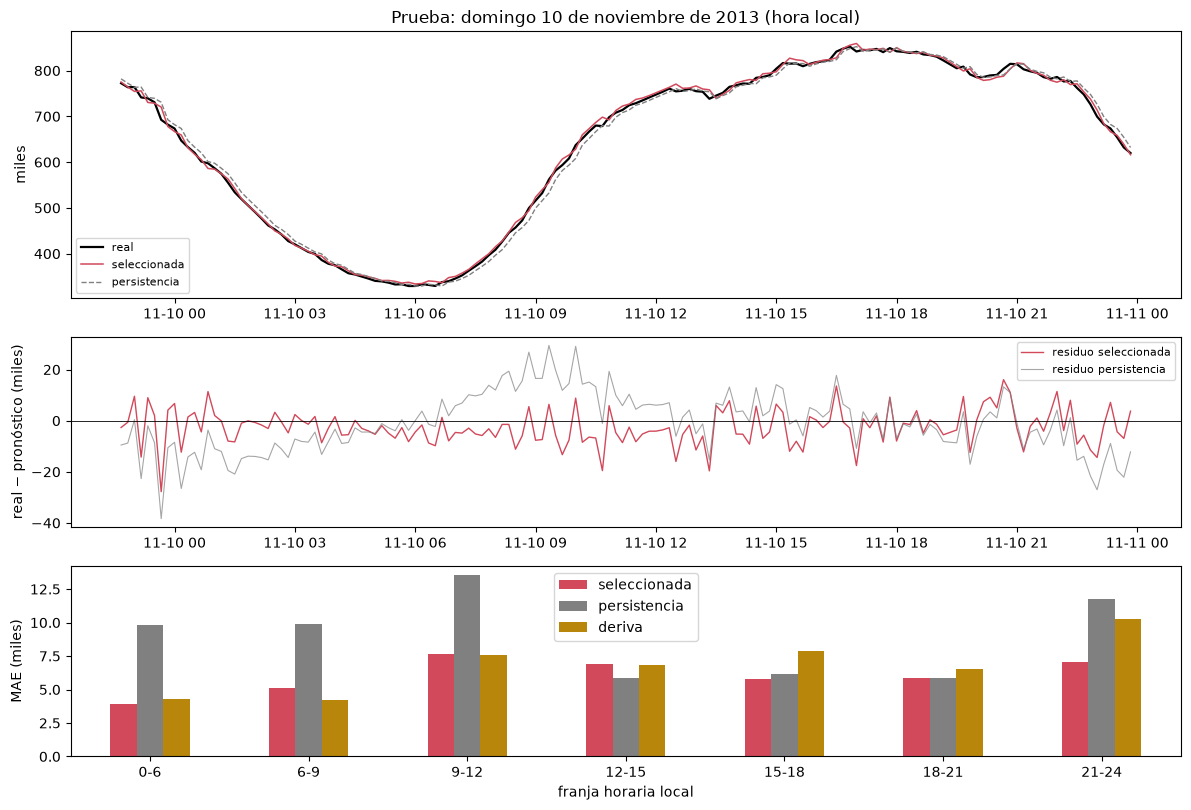

,seleccionada,persistencia,deriva
ts_local,,,
0-6,3883.0,9815.0,4303.0
6-9,5131.0,9857.0,4232.0
9-12,7622.0,13553.0,7557.0
12-15,6899.0,5841.0,6827.0
15-18,5793.0,6194.0,7898.0
18-21,5864.0,5845.0,6531.0
21-24,7058.0,11784.0,10260.0


In [17]:
t_te = df.ts_local.iloc[idx[m_te]].reset_index(drop=True)
e_mod = yt - P_FINAL[m_te]; e_per = yt - PRED_BASE["Persistencia"][m_te]; e_der = yt - PRED_BASE["Deriva"][m_te]
fig, axs = plt.subplots(3, 1, figsize=(12, 8.2), gridspec_kw={"height_ratios": [1.4, 1, 1]})
axs[0].plot(t_te, yt / 1e3, color="black", lw=1.6, label="real")
axs[0].plot(t_te, P_FINAL[m_te] / 1e3, color="#d1495b", lw=1.1, label="seleccionada")
axs[0].plot(t_te, PRED_BASE["Persistencia"][m_te] / 1e3, color="gray", lw=1, ls="--", label="persistencia")
axs[0].set_ylabel("miles"); axs[0].legend(fontsize=8); axs[0].set_title("Prueba: domingo 10 de noviembre de 2013 (hora local)")
axs[1].plot(t_te, e_mod / 1e3, color="#d1495b", lw=1, label="residuo seleccionada")
axs[1].plot(t_te, e_per / 1e3, color="gray", lw=.8, alpha=.7, label="residuo persistencia")
axs[1].axhline(0, color="black", lw=.6); axs[1].set_ylabel("real − pronóstico (miles)"); axs[1].legend(fontsize=8)
hora = t_te.dt.hour
mae_h = pd.DataFrame({"seleccionada": np.abs(e_mod), "persistencia": np.abs(e_per), "deriva": np.abs(e_der), "h": hora}).groupby(
    pd.cut(hora, [0, 6, 9, 12, 15, 18, 21, 24], right=False, labels=["0-6", "6-9", "9-12", "12-15", "15-18", "18-21", "21-24"]),
    observed=False)[["seleccionada", "persistencia", "deriva"]].mean() / 1e3
mae_h.plot.bar(ax=axs[2], color=["#d1495b", "gray", "#b8860b"], rot=0)
axs[2].set_ylabel("MAE (miles)"); axs[2].set_xlabel("franja horaria local")
plt.tight_layout(); plt.savefig(SAL / "fig5_errores_prueba.png", dpi=150); plt.show()
display((mae_h * 1e3).round(0))

In [18]:
from statsmodels.stats.diagnostic import acorr_ljungbox
cambio_real = np.abs(yt - PRED_BASE["Persistencia"][m_te])
q = np.quantile(cambio_real, [1 / 3, 2 / 3])
regimen = np.where(cambio_real <= q[0], "estable", np.where(cambio_real <= q[1], "medio", "rampa"))
tabla_reg = pd.DataFrame({"régimen": regimen, "seleccionada": np.abs(e_mod), "persistencia": np.abs(e_per), "deriva": np.abs(e_der)}
                         ).groupby("régimen")[["seleccionada", "persistencia", "deriva"]].mean().loc[["estable", "medio", "rampa"]]
print("MAE por tercil del cambio real |y_t − y_t-1|:"); display(tabla_reg.round(0))
print(f"Sesgo medio (real − pronóstico): seleccionada {e_mod.mean():,.0f} | persistencia {e_per.mean():,.0f}")
print(f"Percentil 95 del error absoluto: seleccionada {np.quantile(np.abs(e_mod), .95):,.0f} | persistencia {np.quantile(np.abs(e_per), .95):,.0f}")
lb = acorr_ljungbox(e_mod, lags=[1, 6, 12], return_df=True)
print("Ljung-Box de los residuos de la seleccionada:"); display(lb.round(4))
obs = df.observations.to_numpy()[idx[m_te]]
print(f"Correlación |error| vs. cobertura: {np.corrcoef(np.abs(e_mod), obs)[0, 1]:.3f}")
top = pd.DataFrame({"hora_local": t_te.dt.strftime("%a %H:%M"), "real": yt, "pronostico": P_FINAL[m_te], "error": e_mod,
                    "error_persistencia": e_per}).reindex(np.argsort(-np.abs(e_mod))[:5])
print("Cinco errores más grandes:"); display(top.round(0))
# Validación vs. prueba por franja, para separar el efecto fin de semana
e_val = np.abs(y_obj[m_va] - P_FINAL[m_va])
print(f"MAE seleccionada: validación (sábado) {e_val.mean():,.0f} | prueba (domingo) {np.abs(e_mod).mean():,.0f}")

MAE por tercil del cambio real |y_t − y_t-1|:


,seleccionada,persistencia,deriva
régimen,,,
estable,5213.0,2514.0,5674.0
medio,5180.0,7935.0,6258.0
rampa,7098.0,17215.0,8121.0


Sesgo medio (real − pronóstico): seleccionada -2,633 | persistencia -1,066
Percentil 95 del error absoluto: seleccionada 13,872 | persistencia 21,839
Ljung-Box de los residuos de la seleccionada:


,lb_stat,lb_pvalue
1,0.0728,0.7873
6,7.5167,0.2757
12,15.6110,0.2097


Correlación |error| vs. cobertura: 0.186
Cinco errores más grandes:


,hora_local,real,pronostico,error,error_persistencia
6,Sat 23:40,692488.0,720254.0,-27766.0,-38315.0
88,Sun 13:20,738427.0,758053.0,-19626.0,-15380.0
72,Sun 10:40,678820.0,698344.0,-19524.0,-1071.0
110,Sun 17:00,841718.0,859273.0,-17556.0,-10820.0
132,Sun 20:40,803759.0,787724.0,16035.0,13233.0


MAE seleccionada: validación (sábado) 5,599 | prueba (domingo) 5,835


**Lectura:**
- La red gana cuando la actividad sube o baja con fuerza: en el tercil de mayor cambio real, su MAE es 7.098 frente a 17.215 de la persistencia (59 % menos). Las mayores ganancias están en la madrugada (0-6 h: 3.883 frente a 9.815) y en la caída de la noche (21-24 h: 7.058 frente a 11.784).
- La red pierde cuando la serie está estable. Ahí la persistencia acierta casi siempre (2.514) y la red predice un cambio que no ocurre (5.213). Entre las 12 y las 15 h del domingo también pierde (6.899 frente a 5.841).
- El residuo medio es −2.633: la red sobrestima la actividad del domingo, porque aprendió los cambios de los días laborales y el domingo tiene menos actividad. Cuatro de los cinco errores más grandes son sobrestimaciones.
- La prueba de Ljung-Box no rechaza la independencia de los residuos (p = 0,79, 0,28 y 0,21 en los rezagos 1, 6 y 12): la red usa la estructura de corto plazo que hay en la ventana. El percentil 95 del error baja de 21.839 a 13.872.
- La correlación entre el error absoluto y la cobertura es baja (0,19), así que la cobertura no explica la mayor parte del error.
- Mejoras posibles: (1) agregar el día de la semana o la cobertura como entradas para corregir el sesgo del fin de semana, lo que exige más semanas de datos; (2) combinar la red con la persistencia según el régimen, porque cada una gana en un tercil distinto; (3) validar con origen móvil (`TimeSeriesSplit`) para estimar la variación entre días.

## 11. Costos computacionales

In [19]:
reg = pd.DataFrame(REGISTRO)
costo = reg.groupby("ronda").agg(entrenamientos=("nombre", "size"), segundos_total=("segundos", "sum"), segundos_medio=("segundos", "mean"))
display(costo.round(1))
fijar_semilla(42)
X_fin = ENTRADAS[cfg.entrada]
m_tmp = construir(cfg.tipo, X_fin.shape[-1], cfg.lr, cfg.dropout, cfg.optimizador)
t0 = time.time(); [m_tmp.predict(X_fin[m_te], verbose=0) for _ in range(20)]; t_inf = (time.time() - t0) / 20
n_par = int(reg[reg.nombre == SEL].parametros.iloc[0])
print(f"Parámetros de la seleccionada: {n_par:,}")
print(f"Inferencia de 152 ventanas: {1000 * t_inf:.1f} ms por modelo ({1000 * t_inf / 152:.2f} ms por ventana); "
      f"la persistencia no tiene costo de entrenamiento ni de inferencia.")
print(f"Búsqueda completa: {reg.segundos.sum() / 60:.1f} min de CPU para {len(reg)} entrenamientos")

,entrenamientos,segundos_total,segundos_medio
ronda,,,
R1,15,36.2,2.4
R2,24,57.9,2.4
R3,108,161.9,1.5


Parámetros de la seleccionada: 3,681
Inferencia de 152 ventanas: 27.9 ms por modelo (0.18 ms por ventana); la persistencia no tiene costo de entrenamiento ni de inferencia.
Búsqueda completa: 4.3 min de CPU para 147 entrenamientos


## 12. Exportación de pesos, registro y verificación de reproducibilidad

In [20]:
# Reentrenamos la configuración seleccionada con cada semilla (es determinista) y guardamos los pesos
guardados = []
for s, modelo in zip(SEMILLAS, entrenar(SEL + "_export", "export", cfg.tipo, cfg.entrada, cfg.objetivo, cfg.lr, cfg.dropout, cfg.optimizador)):
    ruta = MOD / f"modelo_final_{cfg.tipo}_semilla{s}.keras"
    modelo.save(ruta); guardados.append(ruta)
# Verificación: los pesos cargados reproducen el pronóstico de prueba de la selección
p_rec = np.mean([a_nivel(tf.keras.models.load_model(r).predict(X_fin, verbose=0).ravel(), cfg.objetivo) for r in guardados], axis=0)
dif = np.max(np.abs(p_rec[m_te] - P_FINAL[m_te]))
print("Archivos:", [r.name for r in guardados])
print(f"Máxima diferencia entre el pronóstico recargado y el reportado: {dif:.4f} (unidades de internet_sum)")
assert dif < 1.0, "Los pesos guardados no reproducen el resultado"

meta = {"dataset": "Telecom Italia Big Data Challenge, SMS-Call-Internet-MI, 2013-11-04 a 2013-11-10, agregado a 10 min",
        "csv_sha256": sha, "intervalos": int(N), "lookback": LOOKBACK, "cortes": [CORTE1, CORTE2],
        "ventanas": {"entrenamiento": int(m_tr.sum()), "validacion": int(m_va.sum()), "prueba": int(m_te.sum())},
        "semillas": SEMILLAS, "seleccion": SEL, "configuracion": {k: (v.item() if hasattr(v, "item") else v) for k, v in cfg[["tipo", "entrada", "objetivo", "lr", "dropout", "optimizador"]].items()},
        "ensamble_de_semillas": bool(USAR_ENSAMBLE),
        "escaladores": {"nivel_media": float(sc_y.mean_[0]), "nivel_de": float(sc_y.scale_[0]),
                        "cambio_media": float(sc_d.mean_[0]), "cambio_de": float(sc_d.scale_[0])},
        "prueba_MAE": {k: round(float(v), 1) for k, v in tabla_prueba.MAE.items()},
        "versiones": {"python": platform.python_version(), "tensorflow": tf.__version__, "keras": tf.keras.__version__,
                      "scikit-learn": sklearn.__version__, "numpy": np.__version__, "pandas": pd.__version__}}
(MOD / "metadatos_modelo_final.json").write_text(json.dumps(meta, indent=2, ensure_ascii=False))
pd.DataFrame(REGISTRO).to_csv(SAL / "experimentos.csv", index=False)
r_all = resumen(["R1", "R2", "R3"]); r_all.to_csv(SAL / "resumen_configuraciones.csv")
pd.DataFrame({"ts_local": df.ts_local.iloc[idx[m_te]].astype(str).values, "real": yt, "seleccionada": P_FINAL[m_te],
              "persistencia": PRED_BASE["Persistencia"][m_te], "deriva": PRED_BASE["Deriva"][m_te]}).to_csv(SAL / "pronosticos_prueba.csv", index=False)
if USAR_MLFLOW:
    with mlflow.start_run(run_name="evaluacion_final_prueba"):
        mlflow.set_tags({"ronda": "final", "conjunto_prueba": "usado una vez"})
        mlflow.log_params({"seleccion": SEL, "ensamble": USAR_ENSAMBLE})
        mlflow.log_metrics({"test_MAE": float(tabla_prueba.loc["Seleccionada (final)", "MAE"]),
                            "test_RMSE": float(tabla_prueba.loc["Seleccionada (final)", "RMSE"]),
                            "test_MAE_persistencia": float(tabla_prueba.loc["Persistencia", "MAE"])})
        for r in guardados + [SAL / "comparacion_prueba.csv", SAL / "contrastes_prueba.csv"]:
            mlflow.log_artifact(str(r))
print(f"Corridas registradas: {len(REGISTRO)} | MLflow en {'mlruns/' if USAR_MLFLOW else '(no disponible)'}")

Archivos: ['modelo_final_GRU_semilla42.keras', 'modelo_final_GRU_semilla7.keras', 'modelo_final_GRU_semilla2026.keras']
Máxima diferencia entre el pronóstico recargado y el reportado: 0.0000 (unidades de internet_sum)
Corridas registradas: 150 | MLflow en mlruns/


**Lectura:**
- Los pesos guardados reproducen exactamente el pronóstico reportado (diferencia máxima de 0,0000), así que el resultado se puede verificar sin reentrenar.
- La búsqueda completa tomó 4,4 minutos de CPU para 147 entrenamientos, y la inferencia tarda 0,18 ms por ventana. La persistencia y la deriva no tienen costo, de modo que la red se justifica si una mejora de 36,8 % frente a la persistencia es importante para la operación; frente a la deriva, la ventaja no es significativa.
- **Conclusión.** Con la misma partición y las mismas ventanas, la GRU que predice el cambio reduce el MAE de prueba en 36,8 % frente a la persistencia y en 12,7 % frente a Ridge, con significancia estadística. La mejora frente a la deriva (12,8 %) no es significativa con un solo día de prueba.

## Referencias
- Barlacchi, G., De Nadai, M., Larcher, R., Casella, A., Chitic, C., Torrisi, G., Antonelli, F., Vespignani, A., Pentland, A., & Lepri, B. (2015). A multi-source dataset of urban life in the city of Milan and the Province of Trentino. *Scientific Data, 2*, 150055. https://doi.org/10.1038/sdata.2015.55
- Diebold, F. X., & Mariano, R. S. (1995). Comparing predictive accuracy. *Journal of Business & Economic Statistics, 13*(3), 253-263. https://doi.org/10.1080/07350015.1995.10524599
- Goodfellow, I., Bengio, Y., & Courville, A. (2016). *Deep learning*. MIT Press. https://www.deeplearningbook.org/
- Google Developers. (s. f.). *A scientific approach to improving model performance*. https://developers.google.com/machine-learning/guides/deep-learning-tuning-playbook/scientific
- MLflow Project. (s. f.). *MLflow Tracking*. https://mlflow.org/docs/latest/ml/tracking/
- Scikit-learn Developers. (s. f.). *Cross-validation: evaluating estimator performance*. https://scikit-learn.org/stable/modules/cross_validation.html